# Social Network Analysis Metrics — Zachary's Karate Club

**ATSMA Lab Component**

**Aim.** Compute and interpret the core centrality metrics of social network analysis
— **degree, closeness, betweenness and eigenvector (with PageRank)** — on a real social
network, and test whether these metrics explain how the network actually behaved.

**Dataset.** Zachary's Karate Club ([Network Repository: soc-karate](https://networkrepository.com/soc-karate.php)).
Wayne Zachary recorded the friendships among 34 members of a university karate club
(1970–72). During the study a dispute between the instructor (**Mr. Hi**, node 0) and the
club administrator (**Officer**, node 33) split the club in two. We know which side every
member joined, so we have a **ground truth** to check our analysis against.

**Reference notebook.** The method structure follows
[Fundamentals of Social Network Analysis (Kaggle)](https://www.kaggle.com/code/mexwell/fundamentals-of-social-network-analysis-sna),
which demonstrates the same metrics on a *randomly generated* graph. Here we apply them to
real data, where the results can be interpreted and validated.

### Contents
1. Setup and data
2. Network-level statistics
3. Degree centrality (+ in/out-degree on a directed example)
4. Closeness centrality
5. Betweenness centrality (+ edge betweenness)
6. Eigenvector centrality and PageRank
7. Comparing the metrics
8. Community detection vs the real split
9. Can centrality predict the split?
10. Robustness: what happens if key members leave?
11. Conclusions

## 1. Setup and data

In [1]:
import random
from itertools import islice

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110
SEED = 42
print("networkx", nx.__version__)

networkx 3.7


NetworkX ships the karate club graph, including the faction each member joined (`club`)
and an edge `weight` (how many contexts the two members interacted in).
NetworkX numbers members **0–33**; the paper and the Network Repository file use **1–34**.

In [2]:
G = nx.karate_club_graph()
nodes = pd.DataFrame({"club": nx.get_node_attributes(G, "club")}).rename_axis("node")
edges = nx.to_pandas_edgelist(G)

print(f"{G.number_of_nodes()} members, {G.number_of_edges()} friendship ties")
print(nodes["club"].value_counts().to_string())
edges.head()

34 members, 78 friendship ties
club
Mr. Hi     17
Officer    17


,source,target,weight
0,0,1,4
1,0,2,5
2,0,3,3
3,0,4,3
4,0,5,3


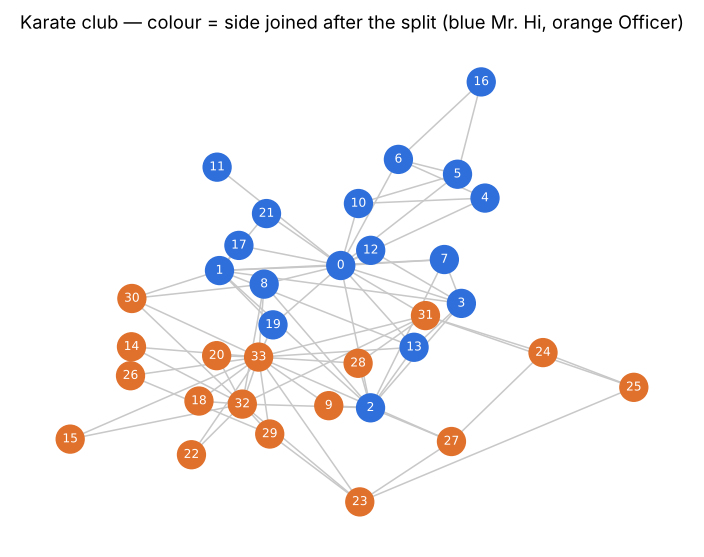

In [3]:
FACTION = {"Mr. Hi": "#2f6fdb", "Officer": "#e0712c"}
pos = nx.kamada_kawai_layout(G)          # fixed layout used for every plot

def draw(values=None, title="", ax=None, cmap="viridis", labels=True):
    ax = ax or plt.gca()
    if values is None:
        color, size, cm = [FACTION[G.nodes[n]["club"]] for n in G], 330, None
    else:
        v = np.array([values[n] for n in G])
        s = (v - v.min()) / (v.max() - v.min())
        color, size, cm = v, 120 + 1100 * s, cmap
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c8c8c8")
    nc = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=color, node_size=size, cmap=cm)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white")
    ax.set_title(title); ax.axis("off")
    return nc

plt.figure(figsize=(8, 6))
draw(title="Karate club — colour = side joined after the split (blue Mr. Hi, orange Officer)")
plt.show()

## 2. Network-level statistics
Before ranking individuals we describe the whole network.

In [4]:
deg = dict(G.degree())
stats = {
    "Nodes": G.number_of_nodes(),
    "Edges": G.number_of_edges(),
    "Density": nx.density(G),
    "Max degree": max(deg.values()),
    "Min degree": min(deg.values()),
    "Average degree": np.mean(list(deg.values())),
    "Degree assortativity": nx.degree_assortativity_coefficient(G),
    "Triangles (unique)": sum(nx.triangles(G).values()) // 3,
    "Average clustering coefficient": nx.average_clustering(G),
    "Transitivity (fraction of closed triangles)": nx.transitivity(G),
    "Max core number": max(nx.core_number(G).values()),
    "Largest clique": max(len(c) for c in nx.find_cliques(G)),
    "Diameter": nx.diameter(G),
    "Average shortest path": nx.average_shortest_path_length(G),
    "Articulation points": sorted(nx.articulation_points(G)),
}
pd.Series(stats, name="value").to_frame()

,value
Nodes,34
Edges,78
Density,0.139
Max degree,17
Min degree,1
Average degree,4.5882
Degree assortativity,-0.4756
Triangles (unique),45
Average clustering coefficient,0.5706
Transitivity (fraction of closed triangles),0.2557


**Cross-check with the Network Repository page.** Density (0.139), max degree (17),
assortativity (−0.476), average clustering (0.571) and fraction of closed triangles (0.256)
match exactly. Two figures look different only because of conventions:
- the repository lists **135 triangles** — it counts each triangle once per corner (45 × 3 = 135);
- it lists a **maximum k-core of 5**; NetworkX's core number is 4 (the 4-core members have
  at least 4 neighbours inside it — some tools report core size as k + 1).

**Reading the numbers**
- **Sparse but small-world:** only 14% of possible ties exist, yet any two members are on
  average **2.4 steps** apart (diameter 5).
- **Highly clustered:** average clustering 0.57 — friends of friends tend to be friends.
- **Negative assortativity (−0.48):** high-degree members mostly connect to low-degree
  members — a hub-and-spoke structure around a few leaders.
- **Node 0 is the only articulation point:** removing Mr. Hi alone cuts off 6 members —
  member 11 and the group {4, 5, 6, 10, 16} — who reach the club only through him.

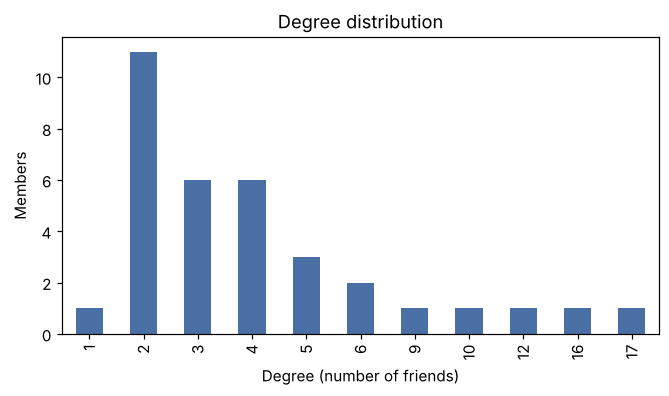

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
pd.Series(deg).value_counts().sort_index().plot.bar(ax=ax, color="#4a6fa5")
ax.set(xlabel="Degree (number of friends)", ylabel="Members", title="Degree distribution")
plt.show()

## 3. Degree centrality
Counts a node's direct connections, normalised by the maximum possible:

$$C_D(v) = \frac{\deg(v)}{n-1}$$

**Meaning:** popularity / immediate reach — how many people a member can talk to directly.

In [6]:
C = pd.DataFrame(index=pd.Index(G.nodes, name="node"))
C["club"] = nodes["club"]
C["friends"] = pd.Series(deg)
C["degree"] = pd.Series(nx.degree_centrality(G))
C.sort_values("degree", ascending=False).head(5)

,club,friends,degree
node,,,
33,Officer,17,0.5152
0,Mr. Hi,16,0.4848
32,Officer,12,0.3636
2,Mr. Hi,10,0.3030
1,Mr. Hi,9,0.2727


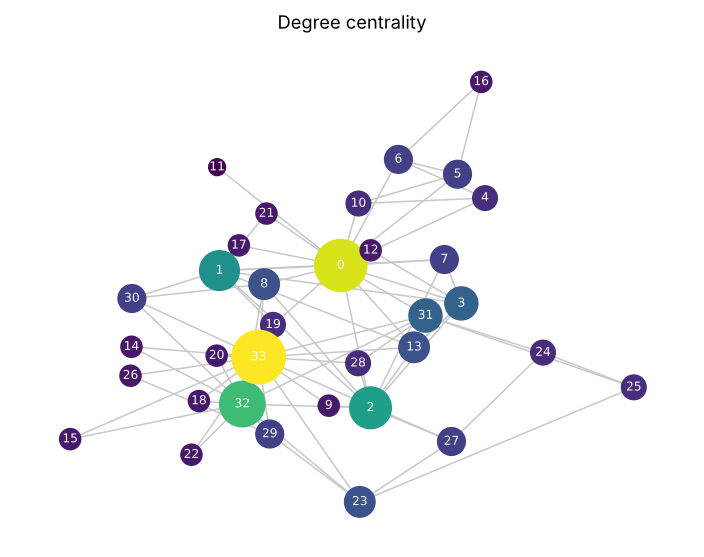

In [7]:
plt.figure(figsize=(8, 6)); draw(C["degree"], "Degree centrality"); plt.show()

**Interpretation.** The two leaders dominate: **node 33 (Officer, 17 friends)** and
**node 0 (Mr. Hi, 16 friends)** — each is directly tied to about half the club. Next come
32 and 2, the leaders' closest lieutenants on each side.

### In-degree and out-degree (directed networks)
The karate network is **undirected** (friendship is mutual), so in/out-degree cannot be
computed on it. To show the concept we use a small *who-follows-whom* network:
- **in-degree** = incoming ties = **popularity**
- **out-degree** = outgoing ties = **activity**

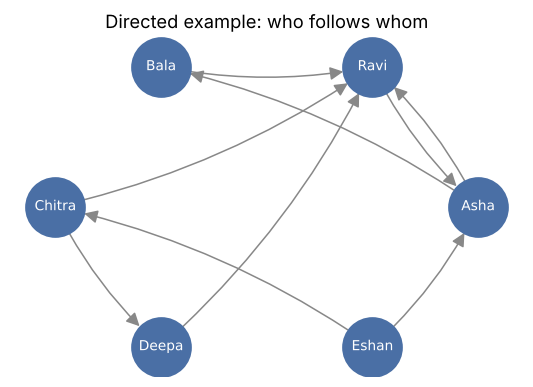

,in-degree (popularity),out-degree (activity),PageRank
Ravi,4,1,0.3724
Asha,2,2,0.3522
Bala,1,1,0.1747
Chitra,1,2,0.0356
Deepa,1,1,0.0401
Eshan,0,2,0.0250


In [8]:
D = nx.DiGraph([("Asha", "Ravi"), ("Bala", "Ravi"), ("Chitra", "Ravi"), ("Deepa", "Ravi"),
                ("Ravi", "Asha"), ("Asha", "Bala"), ("Chitra", "Deepa"),
                ("Eshan", "Chitra"), ("Eshan", "Asha")])
directed = pd.DataFrame({"in-degree (popularity)": dict(D.in_degree()),
                         "out-degree (activity)": dict(D.out_degree()),
                         "PageRank": nx.pagerank(D)}).sort_values("in-degree (popularity)", ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
dpos = nx.circular_layout(D)
nx.draw_networkx(D, dpos, ax=ax, node_color="#4a6fa5", font_color="white", node_size=1500,
                 font_size=9, arrowsize=18, edge_color="#888", connectionstyle="arc3,rad=0.1")
ax.axis("off"); ax.set_title("Directed example: who follows whom"); plt.show()
directed

**Ravi** is the most *popular* (in-degree 4) but not very *active* (out-degree 1);
**Eshan** is active (out-degree 2) but nobody follows him (in-degree 0), so his PageRank is
the lowest. In a directed network the two measures tell different stories.

## 4. Closeness centrality
The inverse of the average shortest-path distance from a node to everyone else:

$$C_C(v) = \frac{n-1}{\sum_{u \neq v} d(v,u)}$$

**Meaning:** how quickly a member can reach — or spread information to — the whole club.

In [9]:
C["closeness"] = pd.Series(nx.closeness_centrality(G))
C["avg_distance"] = 1 / C["closeness"]
C.sort_values("closeness", ascending=False).head(6)[["club", "closeness", "avg_distance"]]

,club,closeness,avg_distance
node,,,
0,Mr. Hi,0.5690,1.7576
2,Mr. Hi,0.5593,1.7879
33,Officer,0.5500,1.8182
31,Officer,0.5410,1.8485
13,Mr. Hi,0.5156,1.9394
8,Mr. Hi,0.5156,1.9394


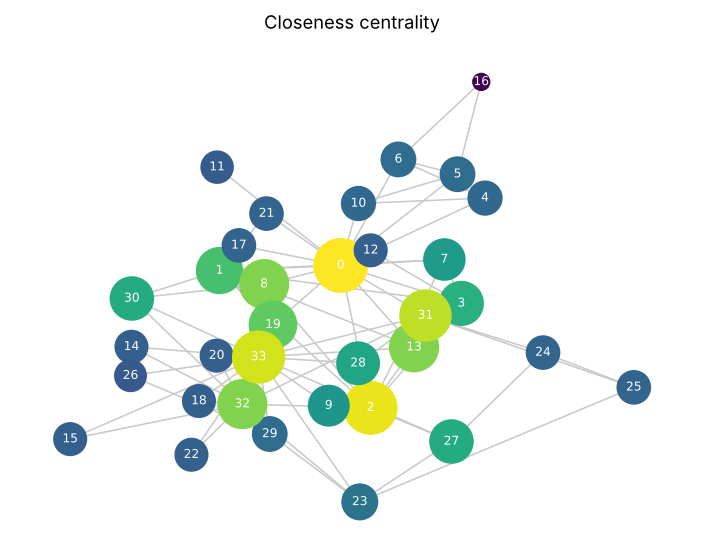

In [10]:
plt.figure(figsize=(8, 6)); draw(C["closeness"], "Closeness centrality"); plt.show()

**Interpretation.** Mr. Hi (0) is the best broadcaster: on average he is **1.76 steps**
from anyone. **Node 2 is a close second** — ahead of the Officer (33) — because it is tied to
members on *both* sides of the club. Closeness values are tightly packed (0.28–0.57) because
the network is small-world: nobody is very far from anybody.

## 5. Betweenness centrality
The share of all shortest paths between other pairs that pass through a node:

$$C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$

where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$ and $\sigma_{st}(v)$
the number of those passing through $v$ (normalised to 0–1 here).

**Meaning:** brokerage — members who act as **bridges or gatekeepers** controlling the flow
of information between groups.

In [11]:
C["betweenness"] = pd.Series(nx.betweenness_centrality(G))
C.sort_values("betweenness", ascending=False).head(6)[["club", "friends", "betweenness"]]

,club,friends,betweenness
node,,,
0,Mr. Hi,16,0.4376
33,Officer,17,0.3041
32,Officer,12,0.1452
2,Mr. Hi,10,0.1437
31,Officer,6,0.1383
8,Mr. Hi,5,0.0559


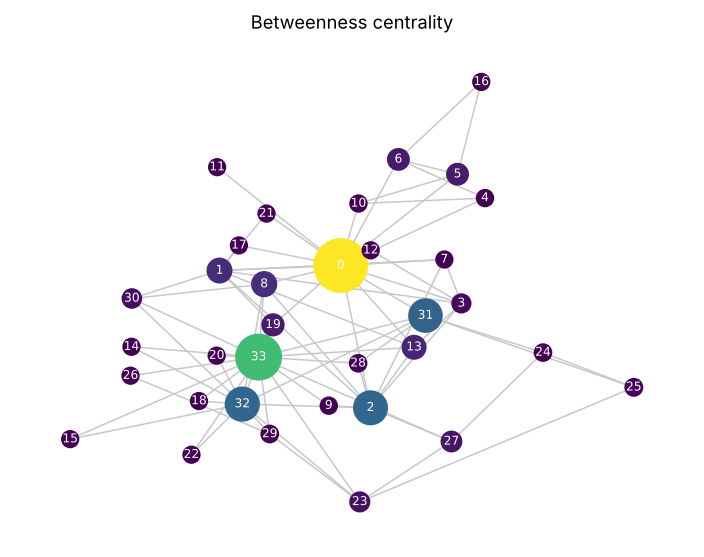

In [12]:
plt.figure(figsize=(8, 6)); draw(C["betweenness"], "Betweenness centrality"); plt.show()

**Interpretation.** Betweenness is the most *concentrated* metric. **Mr. Hi alone lies on
44% of all shortest paths** — far ahead of the Officer (30%) even though the Officer has more
friends. Mr. Hi holds the club together: many members are linked to the rest only through
him (he is the network's only articulation point). Nodes 32, 2 and 31 follow as smaller
bridges between the two camps.

### Edge betweenness
The same idea applied to ties. High-betweenness edges are the bridges the
**Girvan–Newman** algorithm cuts to split a network into communities (Section 8).

In [13]:
eb = nx.edge_betweenness_centrality(G)
top_edges = pd.DataFrame([
    {"edge": e, "betweenness": s,
     "connects": f'{G.nodes[e[0]]["club"]} – {G.nodes[e[1]]["club"]}'}
    for e, s in sorted(eb.items(), key=lambda x: -x[1])[:8]])
top_edges

,edge,betweenness,connects
0,"(0, 31)",0.1273,Mr. Hi – Officer
1,"(0, 6)",0.0781,Mr. Hi – Mr. Hi
2,"(0, 5)",0.0781,Mr. Hi – Mr. Hi
3,"(0, 2)",0.0778,Mr. Hi – Mr. Hi
4,"(0, 8)",0.0742,Mr. Hi – Mr. Hi
5,"(2, 32)",0.0690,Mr. Hi – Officer
6,"(13, 33)",0.0678,Mr. Hi – Officer
7,"(19, 33)",0.0594,Mr. Hi – Officer


## 6. Eigenvector centrality and PageRank
A node is important if it is connected to **other important nodes**. The scores $x$
satisfy the eigenvector equation of the adjacency matrix $A$:

$$x_v = \frac{1}{\lambda} \sum_{u} A_{vu}\, x_u \quad\Longleftrightarrow\quad A\mathbf{x} = \lambda\mathbf{x}$$

**PageRank** (Google's variant) adds a random-jump (damping) factor $d = 0.85$ and divides
each node's influence among its links:

$$PR(v) = \frac{1-d}{n} + d \sum_{u \to v} \frac{PR(u)}{\deg^{out}(u)}$$

**Meaning:** influence — *who you know* matters, not just *how many* you know.

In [14]:
C["eigenvector"] = pd.Series(nx.eigenvector_centrality(G, max_iter=1000))
C["pagerank"] = pd.Series(nx.pagerank(G, alpha=0.85, weight=None))
C.sort_values("eigenvector", ascending=False).head(6)[["club", "friends", "eigenvector", "pagerank"]]

,club,friends,eigenvector,pagerank
node,,,,
33,Officer,17,0.3734,0.1009
0,Mr. Hi,16,0.3555,0.0970
2,Mr. Hi,10,0.3172,0.0571
32,Officer,12,0.3087,0.0717
1,Mr. Hi,9,0.2660,0.0529
8,Mr. Hi,5,0.2274,0.0298


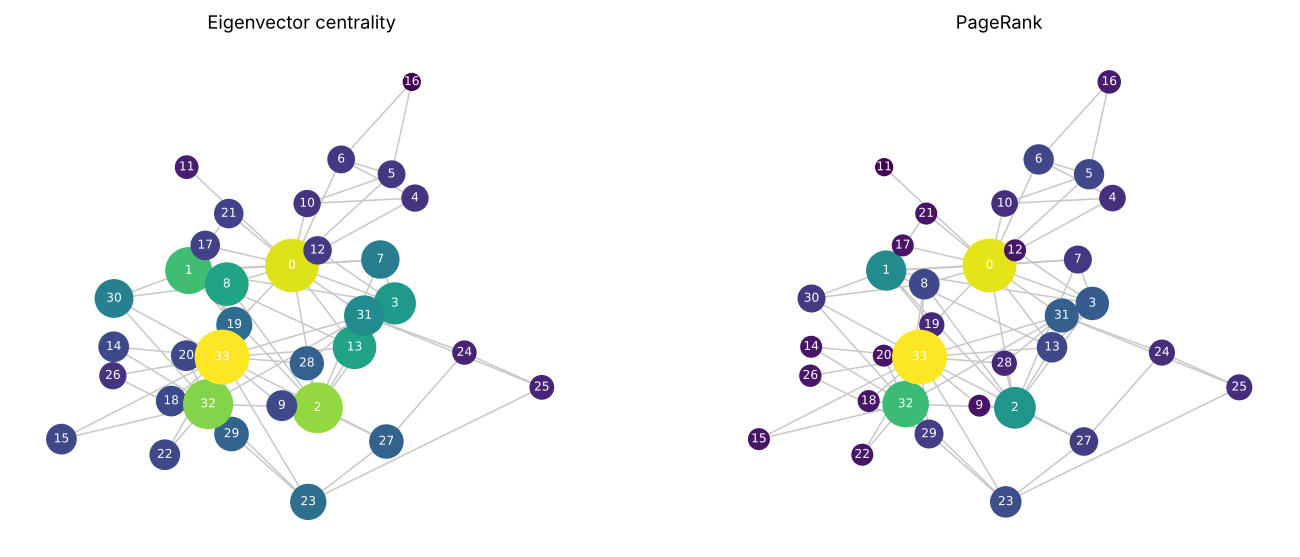

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
draw(C["eigenvector"], "Eigenvector centrality", ax=axes[0])
draw(C["pagerank"], "PageRank", ax=axes[1])
plt.show()

**Interpretation.** The Officer (33) edges out Mr. Hi on influence. **Node 2 rises to 3rd**
on eigenvector despite having only 10 friends, because it is tied to *both* leaders and
their circles. **Node 8** shows the same effect (5 friends, rank 6 on eigenvector).
In an undirected network PageRank closely follows degree, because each node shares its
score among its neighbours.

## 7. Comparing the metrics

In [16]:
METRICS = ["degree", "closeness", "betweenness", "eigenvector", "pagerank"]
ranks = C[METRICS].rank(ascending=False, method="min").astype(int)
ranks.columns = [m + "_rank" for m in METRICS]
summary = C[["club", "friends"] + METRICS].join(ranks)
summary.sort_values("betweenness", ascending=False).head(10)

,club,friends,degree,closeness,betweenness,eigenvector,pagerank,degree_rank,closeness_rank,betweenness_rank,eigenvector_rank,pagerank_rank
node,,,,,,,,,,,,
0,Mr. Hi,16,0.4848,0.5690,0.4376,0.3555,0.0970,2,1,1,2,2
33,Officer,17,0.5152,0.5500,0.3041,0.3734,0.1009,1,3,2,1,1
32,Officer,12,0.3636,0.5156,0.1452,0.3087,0.0717,3,5,3,4,3
2,Mr. Hi,10,0.3030,0.5593,0.1437,0.3172,0.0571,4,2,4,3,4
31,Officer,6,0.1818,0.5410,0.1383,0.1910,0.0372,6,4,5,9,6
8,Mr. Hi,5,0.1515,0.5156,0.0559,0.2274,0.0298,8,5,6,6,9
1,Mr. Hi,9,0.2727,0.4853,0.0539,0.2660,0.0529,5,9,7,5,5
13,Mr. Hi,5,0.1515,0.5156,0.0459,0.2265,0.0295,8,5,8,7,10
19,Mr. Hi,3,0.0909,0.5000,0.0325,0.1479,0.0196,17,8,9,13,21


In [17]:
leaders = pd.DataFrame({m: C[m].sort_values(ascending=False).index[:5].tolist() for m in METRICS},
                       index=[f"#{i}" for i in range(1, 6)])
leaders

,degree,closeness,betweenness,eigenvector,pagerank
#1,33,0,0,33,33
#2,0,2,33,0,0
#3,32,33,32,2,32
#4,2,31,2,32,2
#5,1,13,31,1,1


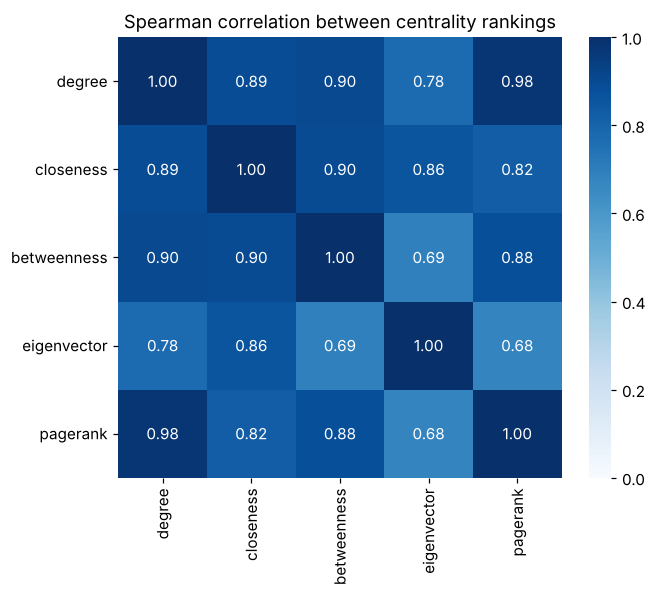

In [18]:
corr = C[METRICS].corr(method="spearman")
plt.figure(figsize=(6.5, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Spearman correlation between centrality rankings"); plt.show()

**What the comparison shows**
- All five metrics agree on the **top two: 0 and 33** — the two leaders whose dispute split
  the club. Centrality identifies the key people without knowing the story.
- They disagree on **who is #1**: the Officer wins on *popularity and influence*
  (degree, eigenvector, PageRank); Mr. Hi wins on *reach and brokerage* (closeness,
  betweenness).
- **Degree and PageRank are almost identical (ρ = 0.98)** — in an undirected network PageRank
  mostly counts friends. Degree and betweenness also agree strongly (0.90), because members
  with one or two friends can never be bridges.
- **Eigenvector is the odd one out** (ρ ≈ 0.68–0.69 with betweenness and PageRank): it
  rewards sitting *inside* the well-connected core around the leaders, while betweenness
  rewards *bridging between* groups — two different ideas of importance.
- **Node 2** is the clearest case of disagreement: modest degree but top-3 in closeness and
  eigenvector — a member bridging both camps.

## 8. Community detection vs the real split
Do the algorithms find the two factions from the friendship structure alone?
We compare each result with the ground truth using:
- **Modularity Q** — quality of the partition (higher = denser inside groups than expected by chance)
- **Accuracy** — map each detected community to its majority faction, then score members
- **ARI / NMI** — standard agreement scores with the true labels (1 = identical)

In [19]:
truth = [0 if G.nodes[n]["club"] == "Mr. Hi" else 1 for n in G]

def labels_of(comms):
    lab = {n: i for i, c in enumerate(comms) for n in c}
    return [lab[n] for n in G]

def majority_accuracy(comms):
    return sum(max(sum(G.nodes[n]["club"] == f for n in c) for f in ("Mr. Hi", "Officer"))
               for c in comms) / G.number_of_nodes()

methods = {
    "Girvan–Newman (2 groups)": next(nx.community.girvan_newman(G)),
    "Louvain": nx.community.louvain_communities(G, seed=SEED),
    "Greedy modularity": nx.community.greedy_modularity_communities(G),
    "Label propagation": list(nx.community.label_propagation_communities(G)),
    "Ground truth": [{n for n in G if G.nodes[n]["club"] == f} for f in ("Mr. Hi", "Officer")],
}
rows, part = [], {}
for name, comms in methods.items():
    lab = labels_of(comms); part[name] = lab
    rows.append({"method": name, "communities": len(comms),
                 "modularity Q": nx.community.modularity(G, comms),
                 "accuracy": majority_accuracy(comms),
                 "ARI": adjusted_rand_score(truth, lab), "NMI": normalized_mutual_info_score(truth, lab)})
comm_table = pd.DataFrame(rows).set_index("method")
comm_table

,communities,modularity Q,accuracy,ARI,NMI
method,,,,,
Girvan–Newman (2 groups),2,0.3477,0.9412,0.7717,0.7324
Louvain,4,0.4266,0.9706,0.4905,0.5942
Greedy modularity,3,0.4110,0.9412,0.5684,0.5646
Label propagation,3,0.3095,0.8529,0.3833,0.3636
Ground truth,2,0.3914,1.0000,1.0000,1.0000


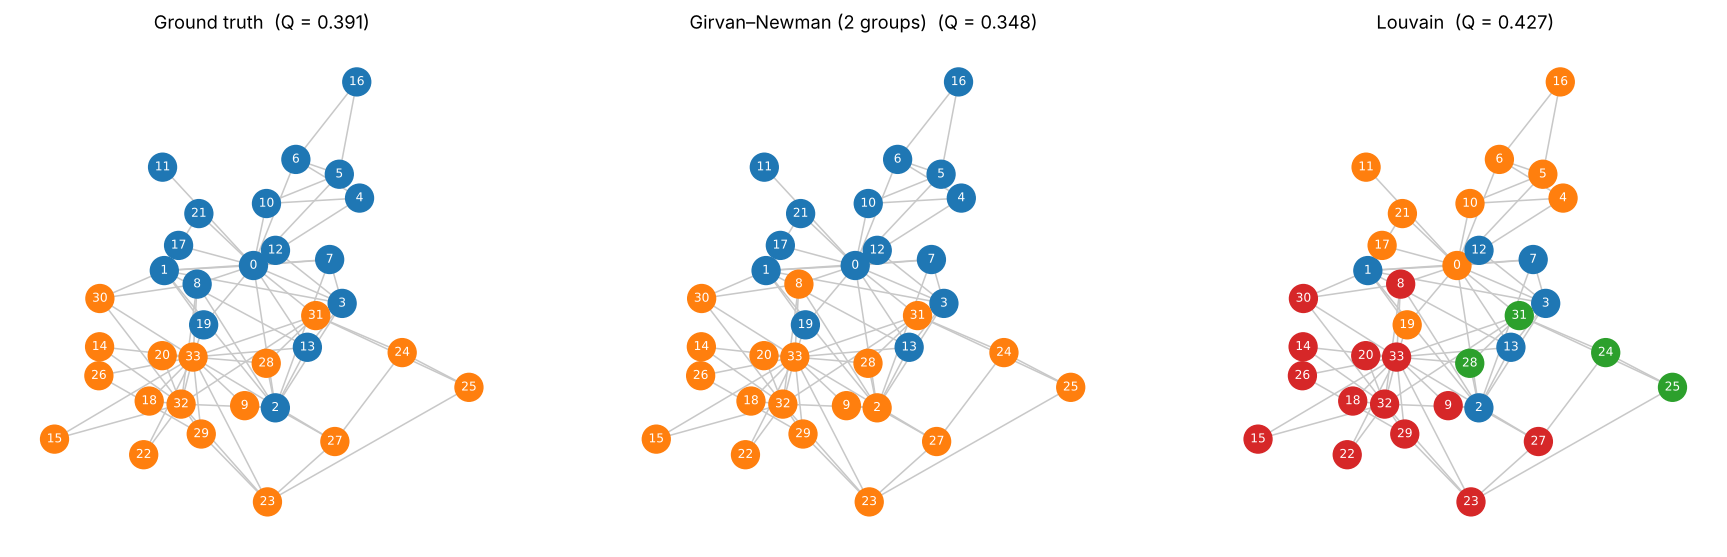

Girvan–Newman misplaced: [2, 8]


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes, ["Ground truth", "Girvan–Newman (2 groups)", "Louvain"]):
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c8c8c8")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=part[name], cmap="tab10", vmin=0, vmax=9, node_size=330)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white")
    ax.set_title(f"{name}  (Q = {comm_table.loc[name, 'modularity Q']:.3f})"); ax.axis("off")
plt.show()

gn = methods["Girvan–Newman (2 groups)"]
gn_side = {n: i for i, c in enumerate(gn) for n in c}
hi_group = gn_side[0]
print("Girvan–Newman misplaced:", [n for n in G if (gn_side[n] == hi_group) != (G.nodes[n]["club"] == "Mr. Hi")])

**Interpretation**
- **Girvan–Newman**, which repeatedly removes the highest-*betweenness* edges, recovers the
  real split with **94% accuracy** — betweenness on its own almost predicts the break-up.
  The two members it misplaces, **2 and 8**, are exactly the "bridge" members flagged by
  closeness and eigenvector in Section 7.
- **Louvain** finds **4 communities** with the highest modularity (0.43): it splits each
  faction into two sub-groups. Every sub-group sits almost entirely inside one faction
  (97% accuracy after mapping), but because it returns 4 groups instead of 2, ARI/NMI are lower.
- Interesting: the true split (Q = 0.39) is **not** the maximum-modularity partition — real
  social splits are not purely structural.

## 9. Can centrality predict the split?
Simple rule: each member joins the leader they are **closer to** (shortest-path distance to
node 0 vs node 33; ties broken by shared friends). Plus a **homophily** check: are friendships
mostly within a faction?

In [21]:
d_hi = nx.single_source_shortest_path_length(G, 0)
d_off = nx.single_source_shortest_path_length(G, 33)
def predict(n):
    if d_hi[n] != d_off[n]:
        return "Mr. Hi" if d_hi[n] < d_off[n] else "Officer"
    hi = len(set(G[n]) & (set(G[0]) | {0})); off = len(set(G[n]) & (set(G[33]) | {33}))
    return "Mr. Hi" if hi >= off else "Officer"

pred = pd.DataFrame({"actual": nodes["club"], "predicted": [predict(n) for n in G],
                     "dist_to_Mr_Hi": pd.Series(d_hi), "dist_to_Officer": pd.Series(d_off)})
print(f"Accuracy: {(pred.actual == pred.predicted).mean():.1%}")
pred[pred.actual != pred.predicted]

Accuracy: 97.1%


,actual,predicted,dist_to_Mr_Hi,dist_to_Officer
8,Mr. Hi,Officer,1,1


In [22]:
same = sum(G.nodes[u]["club"] == G.nodes[v]["club"] for u, v in G.edges)
n_hi = (nodes.club == "Mr. Hi").sum(); n_off = len(nodes) - n_hi; n = len(nodes)
expected = (n_hi*(n_hi-1)/2 + n_off*(n_off-1)/2) / (n*(n-1)/2)
print(f"Ties within the same faction: {same}/{G.number_of_edges()} = {same/G.number_of_edges():.1%}")
print(f"Expected if ties were random:  {expected:.1%}")
print(f"Attribute assortativity (club): {nx.attribute_assortativity_coefficient(G, 'club'):.3f}")

Ties within the same faction: 67/78 = 85.9%
Expected if ties were random:  48.5%
Attribute assortativity (club): 0.718


**Interpretation.** Distance to the two leaders predicts **33 of 34** members correctly.
The only miss is **node 8** (member 9 in the paper): structurally closer to the Officer's
side, he joined Mr. Hi. Zachary's own model misclassified the same member, and Zachary
explained it with a personal reason outside the network — he was close to taking his
black-belt exam under Mr. Hi.

**Homophily is strong:** 86% of friendships are within a faction, versus 48% expected by
chance (assortativity 0.72). The split followed the existing friendship structure.

## 10. Robustness: what happens if key members leave?
Remove members one at a time in order of each centrality and track the share of the club
still in the largest connected group. Compare with removing random members (average of 200 runs).

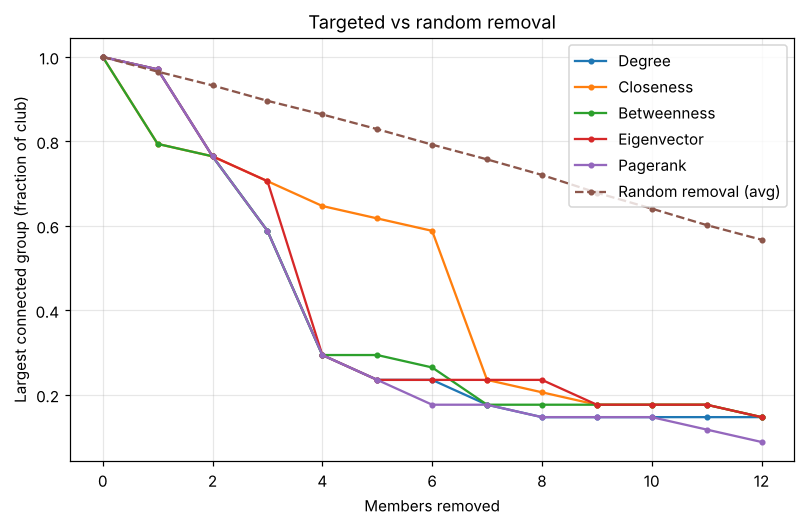

,degree,closeness,betweenness,eigenvector,pagerank,random
removed,,,,,,
0,1.00,1.00,1.00,1.00,1.00,1.00
1,0.97,0.79,0.79,0.97,0.97,0.97
2,0.76,0.76,0.76,0.76,0.76,0.93
3,0.59,0.71,0.59,0.71,0.59,0.90
4,0.29,0.65,0.29,0.29,0.29,0.86
5,0.24,0.62,0.29,0.24,0.24,0.83
6,0.24,0.59,0.26,0.24,0.18,0.79


In [23]:
def lcc_curve(order, k=12):
    H, out = G.copy(), [1.0]
    for v in order[:k]:
        H.remove_node(v)
        out.append(max(len(c) for c in nx.connected_components(H)) / n)
    return out

rng = random.Random(SEED)
curves = {m: lcc_curve(C[m].sort_values(ascending=False).index.tolist()) for m in METRICS}
curves["random"] = np.mean([lcc_curve(rng.sample(list(G), 12)) for _ in range(200)], axis=0)

plt.figure(figsize=(8.5, 5))
for m, ys in curves.items():
    plt.plot(ys, marker="o", ms=3, ls="--" if m == "random" else "-",
             label="Random removal (avg)" if m == "random" else m.capitalize())
plt.xlabel("Members removed"); plt.ylabel("Largest connected group (fraction of club)")
plt.title("Targeted vs random removal"); plt.grid(alpha=.3); plt.legend(); plt.show()

pd.DataFrame({m: [round(x, 2) for x in ys[:7]] for m, ys in curves.items()},
             index=pd.Index(range(7), name="removed"))

**Interpretation.** Removing just the **top 4** members by degree, betweenness, eigenvector
or PageRank shrinks the largest connected group to **29%** of the club. Removing 4 random
members leaves it at about **86%**. The club depends on a handful of central people.
**Betweenness and closeness** start by removing Mr. Hi, and that single removal does the most
damage (100% → 79%) — removing the Officer first barely matters (97%) — confirming Mr. Hi is
the main bridge. Closeness is the weakest strategy after that — it targets members who are
*near* everyone, not those who *hold groups together*.

## 11. Conclusions

| Metric | Measures | Top member | Key finding |
|---|---|---|---|
| **Degree** | popularity (direct ties) | 33 (Officer) | the two leaders each reach ~half the club directly |
| **Closeness** | speed of reaching everyone | 0 (Mr. Hi) | small-world: average distance only 2.4 steps |
| **Betweenness** | brokerage / bridging | 0 (Mr. Hi) | Mr. Hi lies on 44% of shortest paths — the club's main bridge |
| **Eigenvector** | influence via important friends | 33 (Officer) | node 2 ranks 3rd with only 10 friends, through ties to both leaders |
| **PageRank** | influence with damping | 33 (Officer) | follows degree closely in an undirected network |

1. **Every metric identifies the same two leaders (0 and 33)** — the people at the centre of
   the real conflict — from friendship structure alone.
2. The metrics capture **different kinds of importance**: the Officer is more *popular and
   influential*, Mr. Hi is the better *connector*.
3. **Structure predicted the split:** Girvan–Newman (betweenness-based) recovered it with
   94% accuracy, and distance to the two leaders with 97%.
4. **The network is fragile to targeted removal:** losing 4 central members disconnects most
   of the club, while losing 4 random members barely matters.

**Limitations.** The network is small (34 members) and undirected, so in/out-degree is shown
on a separate example. Centrality describes position, not motive — the one member every model
misses changed sides for a personal reason.

**References**
- Zachary, W. W. (1977). *An information flow model for conflict and fission in small groups.*
  Journal of Anthropological Research, 33(4), 452–473.
- Rossi, R. A. & Ahmed, N. K. (2015). *The Network Data Repository with Interactive Graph
  Analytics and Visualization.* AAAI. https://networkrepository.com
- mexwell. *Fundamentals of Social Network Analysis (SNA)*, Kaggle.
- Hagberg, Schult & Swart (2008). *Exploring network structure, dynamics, and function using NetworkX.*